
Cells and independent roots by stage and tissue:
                   II - IV | G  II - IV | V  Stage VI | G  Stage VI | V  Stage VI | RA  PR | G  PR | V
metric                                                                                                
cells                       77           62            23            35             18     105      80
independent_roots           13           14             3             3              3       1       1
Applied intensity filter: weight >= 0.20 | kept 294/400 points (73.5%)


NameError: name 'wts_plot' is not defined

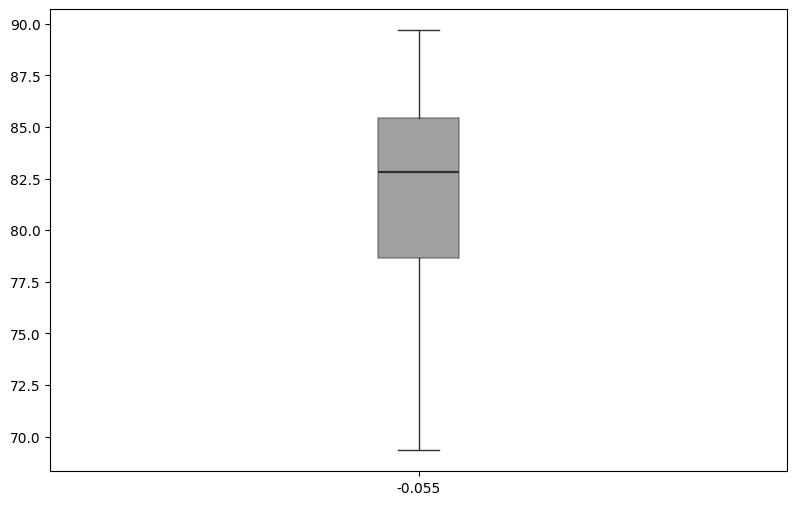

In [ ]:
# Final boxplot: Stage II-IV/VI grouped layout plus mature-root (MT-PR only) V/G split by labelled tissue
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from xml.etree import ElementTree as ET

try:
    from statsmodels.stats.multicomp import pairwise_tukeyhsd
except Exception as exc:
    raise RuntimeError("statsmodels is required for Tukey HSD. Install/import statsmodels first.") from exc

DATAFILE = "MT/data_redone_after_reordering_and_verification_layers.xlsx"
MR_DATAFILE = "MT/MT-PR.ods"
MR_STAGE_LABEL = "PR"

df = pd.read_excel(DATAFILE)
stages = [2, 3, 4, 5, 6]
df = df[df["stage"].isin(stages)].copy()

stage_tissue_aliases = {
    "tissue": ["tissue", "Tissue"],
}
for target_col, candidates in stage_tissue_aliases.items():
    if target_col not in df.columns:
        for candidate_col in candidates:
            if candidate_col in df.columns:
                df[target_col] = df[candidate_col]
                break
        else:
            raise RuntimeError(f"Missing required tissue column {target_col}. Available columns: {list(df.columns)}")

df["tissue"] = df["tissue"].astype(str).str.strip().str.upper().replace({"NAN": "", "NONE": ""})
df["stage"] = pd.to_numeric(df["stage"], errors="coerce")
df["anisotropy"] = pd.to_numeric(df["anisotropy"], errors="coerce")
orientation_source = "orientation flipped for bottom half" if "orientation flipped for bottom half" in df.columns else None
if orientation_source is None or pd.to_numeric(df[orientation_source], errors="coerce").notna().sum() == 0:
    for candidate_col in ["average fibril orientation", "orientation"]:
        if candidate_col in df.columns and pd.to_numeric(df[candidate_col], errors="coerce").notna().sum() > 0:
            orientation_source = candidate_col
            break
if orientation_source is None:
    raise RuntimeError(f"No usable orientation column found. Available columns: {list(df.columns)}")
df[orientation_source] = pd.to_numeric(df[orientation_source], errors="coerce")


def classify_selected_group(stage, tissue):
    if pd.isna(stage):
        return None
    stage = int(stage)
    tissue = str(tissue).strip().upper()
    if stage in {2, 3, 4}:
        if tissue == "G":
            return "S2_G"
        if tissue == "V":
            return "S2_V"
    if stage == 6:
        if tissue == "G":
            return "S6_G"
        if tissue == "V":
            return "S6_V"
        if tissue in {"A", "RA"}:
            return "S6_RA"
    return None


def classify_mr_group_from_tissue(tissue):
    tissue = str(tissue).strip().upper()
    if tissue == "V":
        return "MR_V"
    if tissue == "G":
        return "MR_G"
    return None


def to_acute_axial_deg(angle_deg):
    a = np.asarray(angle_deg, dtype=float)
    return np.abs(((a + 90.0) % 180.0) - 90.0)


def cld_letters_from_significance(sig_matrix):
    n = sig_matrix.shape[0]
    columns = [set(range(n))]
    sig_pairs = [(i, j) for i in range(n) for j in range(i + 1, n) if sig_matrix[i, j]]
    for i, j in sig_pairs:
        new_cols = []
        for col in columns:
            if i in col and j in col:
                c1 = set(col)
                c1.remove(j)
                c2 = set(col)
                c2.remove(i)
                if c1:
                    new_cols.append(c1)
                if c2:
                    new_cols.append(c2)
            else:
                new_cols.append(set(col))
        unique_cols = []
        seen = set()
        for c in new_cols:
            key = tuple(sorted(c))
            if key not in seen:
                seen.add(key)
                unique_cols.append(c)
        maximal = []
        for c in unique_cols:
            if not any((c < d) for d in unique_cols):
                maximal.append(c)
        columns = maximal
    alphabet = list("abcdefghijklmnopqrstuvwxyz")
    letters = ["" for _ in range(n)]
    for col_idx, col in enumerate(columns):
        letter = alphabet[col_idx]
        for i in sorted(col):
            letters[i] += letter
    return letters


def weighted_expand(values, weights, scale=20, min_rep=1, max_rep=20):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    if len(values) == 0:
        return np.array([], dtype=float)
    reps = np.rint(np.clip(weights, 0, 1) * scale).astype(int)
    reps = np.clip(reps, min_rep, max_rep)
    return np.repeat(values, reps)


def weighted_quantile(values, weights, quantiles):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    quantiles = np.asarray(quantiles, dtype=float)
    if len(values) == 0:
        return np.full(len(quantiles), np.nan)
    mask = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values = values[mask]
    weights = weights[mask]
    if len(values) == 0:
        return np.full(len(quantiles), np.nan)
    order = np.argsort(values)
    values = values[order]
    weights = weights[order]
    cdf = np.cumsum(weights)
    total = cdf[-1]
    if total <= 0:
        return np.full(len(quantiles), np.nan)
    cdf_mid = (cdf - 0.5 * weights) / total
    cdf_mid = np.clip(cdf_mid, 0, 1)
    return np.interp(quantiles, cdf_mid, values)


def expand_by_weights(values, weights, target_n=4000):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    mask = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values = values[mask]
    weights = weights[mask]
    if len(values) == 0:
        return np.array([], dtype=float)
    total = np.sum(weights)
    if total <= 0:
        return np.array([], dtype=float)
    probs = weights / total
    scaled = probs * float(target_n)
    reps = np.floor(scaled).astype(int)
    remainder = int(target_n - np.sum(reps))
    if remainder > 0:
        frac = scaled - reps
        top_idx = np.argsort(frac)[-remainder:]
        reps[top_idx] += 1
    if np.sum(reps) == 0:
        reps[np.argmax(weights)] = 1
    return np.repeat(values, reps)


def weighted_box_stats(values, weights, whis=1.5, expand_target=4000):
    expanded = expand_by_weights(values, weights, target_n=expand_target)
    if len(expanded) == 0:
        return None
    q1, med, q3 = np.percentile(expanded, [25, 50, 75])
    iqr = q3 - q1
    lo_bound = q1 - whis * iqr
    hi_bound = q3 + whis * iqr
    inliers = expanded[(expanded >= lo_bound) & (expanded <= hi_bound)]
    if len(inliers):
        whislo = float(np.min(inliers))
        whishi = float(np.max(inliers))
    else:
        whislo = float(np.min(expanded))
        whishi = float(np.max(expanded))
    return {"med": float(med), "q1": float(q1), "q3": float(q3), "whislo": whislo, "whishi": whishi, "fliers": []}


def first_existing_column(frame, candidates):
    for col in candidates:
        if col in frame.columns:
            return col
    return None


def parse_mtpr_ods(path):
    ns = {
        "table": "urn:oasis:names:tc:opendocument:xmlns:table:1.0",
        "office": "urn:oasis:names:tc:opendocument:xmlns:office:1.0",
    }
    columns = [
        "file name",
        "ROI number",
        "x-coordinate of ROI centre",
        "y-coordinate of ROI centre",
        "ROI surface area",
        "average fibril orientation",
        "anisotropy",
        "stage",
        "tissue"
    ]

    with zipfile.ZipFile(path) as zf:
        root = ET.fromstring(zf.read("content.xml"))

    table = root.find(".//table:table", ns)
    if table is None:
        raise RuntimeError(f"No table found in MT-PR file: {path}")

    rows = []
    for row in table.findall("table:table-row", ns):
        values = []
        for cell in row:
            if cell.tag not in {f"{{{ns['table']}}}table-cell", f"{{{ns['table']}}}covered-table-cell"}:
                continue
            repeat = int(cell.attrib.get(f"{{{ns['table']}}}number-columns-repeated", "1"))
            text = "".join((part or "") for part in cell.itertext()).strip()
            if not text:
                text = cell.attrib.get(f"{{{ns['office']}}}value", "")
            values.extend([text] * repeat)
        while values and values[-1] == "":
            values.pop()
        if values:
            rows.append(values[:len(columns)])

    if not rows:
        raise RuntimeError(f"MT-PR file contained no readable rows: {path}")

    padded_rows = [row + [""] * (len(columns) - len(row)) for row in rows]
    return pd.DataFrame(padded_rows, columns=columns)


def load_mature_root_points_from_mtpr(path):
    try:
        mr_df = pd.read_excel(path, engine="odf")
    except Exception:
        mr_df = parse_mtpr_ods(path)

    col_root = first_existing_column(mr_df, [
        "file name",
        "file",
        "image",
    ])
    col_angle = first_existing_column(mr_df, [
        "average fibril orientation",
        "orientation flipped for bottom half",
        "orientation",
    ])
    col_weight = first_existing_column(mr_df, [
        "anisotropy",
    ])
    col_stage = first_existing_column(mr_df, [
        "stage",
    ])
    col_tissue = first_existing_column(mr_df, [
        "tissue"
    ])

    required = {"root": col_root, "angle": col_angle, "weight": col_weight, "tissue": col_tissue}
    missing = [k for k, v in required.items() if v is None]
    if missing:
        raise RuntimeError(
            f"Missing required MT-PR columns: {missing}. Available columns: {list(mr_df.columns)}"
        )

    if col_stage is not None:
        stage_text = mr_df[col_stage].astype(str).str.strip().str.upper()
        mr_df = mr_df[stage_text == str(MR_STAGE_LABEL).upper()].copy()

    mr_df[col_root] = mr_df[col_root].astype(str).str.strip()
    mr_df[col_angle] = pd.to_numeric(mr_df[col_angle], errors="coerce")
    mr_df[col_weight] = pd.to_numeric(mr_df[col_weight], errors="coerce")
    mr_df[col_tissue] = mr_df[col_tissue].astype(str).str.strip().str.upper()
    mr_df = mr_df.dropna(subset=[col_angle, col_weight]).copy()

    if mr_df.empty:
        raise RuntimeError("MT-PR mature-root table produced no usable rows after cleaning.")

    mr_df["selected_group"] = mr_df[col_tissue].apply(classify_mr_group_from_tissue)
    mr_df["value"] = to_acute_axial_deg(mr_df[col_angle].to_numpy(dtype=float))
    mr_df["weight_raw"] = pd.to_numeric(mr_df[col_weight], errors="coerce")
    mr_df["root_id"] = mr_df[col_root]
    mr_df["stage_label"] = "PR"
    mr_df["tissue_label"] = mr_df[col_tissue]
    mr_df = mr_df[(mr_df["root_id"] != "")].dropna(subset=["selected_group", "value", "weight_raw"]).copy()

    if mr_df.empty:
        raise RuntimeError("MT-PR mature-root rows exist, but no valid labelled tissue, angle, anisotropy, or root identifiers were found.")

    return mr_df[["selected_group", "value", "weight_raw", "root_id", "stage_label", "tissue_label"]].copy()


plot_order = ["S2_G", "S2_V", "S6_G", "S6_V", "S6_RA", "MR_G", "MR_V"]
short_label = {"S2_G": "G", "S2_V": "V", "S6_G": "G", "S6_V": "V", "S6_RA": "RA", "MR_G": "G", "MR_V": "V"}
group_to_tissue = {"S2_V": "V", "S2_G": "G", "S6_V": "V", "S6_G": "G", "S6_RA": "RA", "MR_V": "V", "MR_G": "G"}
group_to_stage_label = {
    "S2_G": "II - IV",
    "S2_V": "II - IV",
    "S6_G": "Stage VI",
    "S6_V": "Stage VI",
    "S6_RA": "Stage VI",
    "MR_G": "PR",
    "MR_V": "PR",
}
tissue_colors = {"V": "#b8b8b8", "G": "#2f2f2f", "RA": "#1f1f1f"}

stage_centers = {"S2": 0.0, "S6": 0.72, "MR": 1.44}
within_offsets = {
    "S2_G": -0.055,
    "S2_V": 0.055,
    "S6_G": -0.11,
    "S6_V": 0.00,
    "S6_RA": 0.11,
    "MR_G": -0.055,
    "MR_V": 0.055,
}
box_width = 0.11
point_jitter = 0.02
point_alpha = 0.28
box_alpha = 0.45
alpha_sig = 0.05
weight_scale = 20
min_rep = 1
max_rep = 20
min_intensity_keep = 0.2
min_point_size = 8
max_point_size = 46

x_pos = {}
for g in plot_order:
    if g.startswith("S2_"):
        x_pos[g] = stage_centers["S2"] + within_offsets[g]
    elif g.startswith("S6_"):
        x_pos[g] = stage_centers["S6"] + within_offsets[g]
    elif g.startswith("MR_"):
        x_pos[g] = stage_centers["MR"] + within_offsets[g]
    else:
        raise RuntimeError(f"Unknown group key in plot_order: {g}")

stage_root_col = first_existing_column(df, [
    "file name",
    "file",
    "image",
])
if stage_root_col is None:
    raise RuntimeError(f"No usable root identifier column found in stage data. Available columns: {list(df.columns)}")

work_df = df.copy()
work_df["selected_group"] = work_df.apply(lambda r: classify_selected_group(r["stage"], r["tissue"]), axis=1)
work_df = work_df[work_df["selected_group"].isin(plot_order)].copy()
work_df["value"] = to_acute_axial_deg(work_df[orientation_source].to_numpy(dtype=float))
work_df["weight_raw"] = pd.to_numeric(work_df["anisotropy"], errors="coerce")
work_df["root_id"] = work_df[stage_root_col].astype(str).str.strip()
work_df["stage_label"] = work_df["selected_group"].map(group_to_stage_label)
work_df["tissue_label"] = work_df["selected_group"].map(group_to_tissue)
work_df = work_df[(work_df["root_id"] != "")].dropna(subset=["value", "weight_raw"]).copy()

mr_df = load_mature_root_points_from_mtpr(MR_DATAFILE)
work_df = pd.concat([
    work_df[["selected_group", "value", "weight_raw", "root_id", "stage_label", "tissue_label"]],
    mr_df[["selected_group", "value", "weight_raw", "root_id", "stage_label", "tissue_label"]],
], ignore_index=True)

if work_df.empty:
    raise RuntimeError("No data matched the requested stage+tissue selections.")

summary_df = work_df.groupby(["stage_label", "tissue_label"], as_index=False).agg(
    cells=("selected_group", "size"),
    independent_roots=("root_id", "nunique"),
)
summary_df["stage_label"] = pd.Categorical(summary_df["stage_label"], categories=["II - IV", "Stage VI", "PR"], ordered=True)
summary_df["tissue_label"] = pd.Categorical(summary_df["tissue_label"], categories=["G", "V", "RA"], ordered=True)
summary_df = summary_df.sort_values(["stage_label", "tissue_label"]).reset_index(drop=True)
summary_wide_df = summary_df.set_index(["stage_label", "tissue_label"])[["cells", "independent_roots"]].T
summary_wide_df.columns = [f"{stage} | {tissue}" for stage, tissue in summary_wide_df.columns]
summary_wide_df.index.name = "metric"
print("\nCells and independent roots by stage and tissue:")
print(summary_wide_df.to_string())

group_max = work_df.groupby("selected_group")["weight_raw"].transform("max")
work_df["weight"] = np.where(group_max > 0, np.clip(work_df["weight_raw"] / group_max, 0.0, 1.0), 0.0)
n_total_points = len(work_df)
work_df = work_df[work_df["weight"] >= min_intensity_keep].copy()
n_kept_points = len(work_df)
print(f"Applied intensity filter: weight >= {min_intensity_keep:.2f} | kept {n_kept_points}/{n_total_points} points ({100.0 * n_kept_points / n_total_points:.1f}%)")

fig, ax = plt.subplots(1, 1, figsize=(9.5, 6))
all_values, all_weights, expanded_groups, annotation_tops = [], [], [], []
for g in plot_order:
    sub = work_df[work_df["selected_group"] == g]
    vals = sub["value"].to_numpy(dtype=float)
    wts = sub["weight"].to_numpy(dtype=float)
    if len(vals) == 0:
        expanded_groups.append(np.array([], dtype=float))
        continue

    all_values.extend(vals.tolist())
    all_weights.extend(wts.tolist())
    xp = x_pos[g]
    c = tissue_colors[group_to_tissue[g]]

    stats = weighted_box_stats(vals, wts, whis=1.5, expand_target=4000)
    if stats is not None:
        bp = ax.bxp([stats], positions=[xp], widths=box_width, patch_artist=True, showfliers=False,
                    medianprops={"color": c, "linewidth": 1.6},
                    whiskerprops={"color": c, "linewidth": 1.0},
                    capprops={"color": c, "linewidth": 1.0},
                    boxprops={"edgecolor": c, "linewidth": 1.2})
        for patch in bp["boxes"]:
            patch.set_facecolor(c)
            patch.set_alpha(box_alpha)

    n_plot = min(len(vals), 2500)
    if len(vals) > n_plot:
        sel = np.random.choice(np.arange(len(vals)), size=n_plot, replace=False)
        vals_plot = vals[sel]
        wts_plot = wts[sel]
    else:
        vals_plot = vals
        wts_plot = wts
    sizes = min_point_size + (max_point_size - min_point_size) * np.clip(wts_plot, 0, 1)
    jitter = np.random.uniform(-point_jitter, point_jitter, size=len(vals_plot))
    ax.scatter(np.full(len(vals_plot), xp) + jitter, vals_plot, s=sizes, color=c, alpha=point_alpha, zorder=3)

    mean_val = np.average(vals, weights=wts) if np.sum(wts) > 0 else np.mean(vals)
    ax.plot([xp], [mean_val], marker="o", linewidth=2.0, markersize=4.8, color=c, zorder=5)
    ax.text(xp, -0.07, short_label[g], ha="center", va="top", fontsize=9, color=c, transform=ax.get_xaxis_transform(), clip_on=False)
    ax.text(xp, -0.12, f"n={len(vals)}", ha="center", va="top", fontsize=8, color=c, transform=ax.get_xaxis_transform(), clip_on=False)

    expanded_groups.append(weighted_expand(vals, wts, scale=weight_scale, min_rep=min_rep, max_rep=max_rep))

sig = np.zeros((len(plot_order), len(plot_order)), dtype=bool)
flat_values, flat_groups = [], []
for i, arr in enumerate(expanded_groups):
    if len(arr) == 0:
        continue
    flat_values.extend(arr.tolist())
    flat_groups.extend([i] * len(arr))

if len(set(flat_groups)) >= 2:
    tukey = pairwise_tukeyhsd(endog=np.asarray(flat_values, dtype=float), groups=np.asarray(flat_groups), alpha=alpha_sig)
    print("\nTukey HSD (including MT-PR mature root groups):")
    rows = []
    for row in tukey.summary().data[1:]:
        i = int(float(row[0]))
        j = int(float(row[1]))
        reject = bool(row[6])
        sig[i, j] = sig[j, i] = reject
        rows.append({"group_i": plot_order[i], "group_j": plot_order[j], "significant": reject})
    print(pd.DataFrame(rows).to_string(index=False))

letters = cld_letters_from_significance(sig)
for i, arr in enumerate(expanded_groups):
    if len(arr) == 0:
        continue
    g = plot_order[i]
    c = tissue_colors[group_to_tissue[g]]
    y_text = float(np.max(arr) + 1.0)
    ax.text(x_pos[g], y_text, letters[i], ha="center", va="bottom", fontsize=10, fontweight="bold", color=c, zorder=6)
    annotation_tops.append(y_text)

if len(all_values) and len(all_weights):
    q1, q99 = weighted_quantile(np.asarray(all_values, dtype=float), np.asarray(all_weights, dtype=float), [0.01, 0.99])
    y0 = max(0.0, float(q1) - 2.0)
    y1_base = float(q99) + 4.0
else:
    y0, y1_base = 0.0, 90.0

y1 = min(90.0, max(y1_base, (max(annotation_tops) if annotation_tops else y1_base) + 1.0))

ax.set_xlim(-0.30, 1.70)
ax.set_xticks([stage_centers["S2"], stage_centers["S6"], stage_centers["MR"]])
ax.set_xticklabels(["II - IV", "Stage VI", "Mature roots"])
ax.set_ylim(y0, y1)
ax.set_ylabel("Cell angle (degrees)")
ax.set_title("Thin boxplots with grouped stage spacing + MT-PR mature-root V/G")
ax.grid(axis="y", linestyle=":", alpha=0.4)

fig.tight_layout(rect=[0, 0, 1, 0.95])
output_dir = Path("figures")
output_dir.mkdir(exist_ok=True)
out_file = output_dir / "boxplot_stage2_stage6_matureroot_mtpr_vg.svg"
fig.savefig(out_file, format="svg", bbox_inches="tight")
print(f"Saved: {out_file}")
print("\nCounts:")
print(work_df.groupby("selected_group").size().reindex(plot_order, fill_value=0).to_string())

plt.show()